In [4]:
import pandas as pd
import numpy as np 

from pathlib import Path

In [5]:
import sys
import pandas as pd
import numpy as np
import sklearn
import xgboost

print("Python:", sys.version)
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Scikit-learn:", sklearn.__version__)
print("XGBoost:", xgboost.__version__)

Python: 3.10.6 (tags/v3.10.6:9c7b4bd, Aug  1 2022, 21:53:49) [MSC v.1932 64 bit (AMD64)]
Pandas: 2.3.3
NumPy: 2.2.6
Scikit-learn: 1.7.2
XGBoost: 3.2.0


In [6]:
DATA_DIR = Path("../../data/raw")

In [7]:
train = pd.read_csv(
    DATA_DIR / "train.csv",
    parse_dates=["date"]
)

test = pd.read_csv(
    DATA_DIR / "test.csv",
    parse_dates=["date"]
)

stores = pd.read_csv(DATA_DIR / "stores.csv")

transactions = pd.read_csv(
    DATA_DIR / "transactions.csv",
    parse_dates=["date"]
)

oil = pd.read_csv(
    DATA_DIR / "oil.csv",
    parse_dates=["date"]
)

holidays = pd.read_csv(
    DATA_DIR / "holidays_events.csv",
    parse_dates=["date"]
)

In [8]:
datasets = {
    "train": train,
    "test": test,
    "stores": stores,
    "transactions": transactions,
    "oil": oil,
    "holidays": holidays
}

for name, df in datasets.items():
    print(
        f"{name:15} | "
        f"Rows: {len(df):>10,} | "
        f"Columns: {len(df.columns)}"
    )

train           | Rows:  3,000,888 | Columns: 6
test            | Rows:     28,512 | Columns: 5
stores          | Rows:         54 | Columns: 5
transactions    | Rows:     83,488 | Columns: 3
oil             | Rows:      1,218 | Columns: 2
holidays        | Rows:        350 | Columns: 6


In [9]:
train_fe = train.merge(
    stores,
    on="store_nbr",
    how="left",
    validate="many_to_one"
)

test_fe = test.merge(
    stores,
    on="store_nbr",
    how="left",
    validate="many_to_one"
)

print("Train:", train_fe.shape)
print("Test :", test_fe.shape)

Train: (3000888, 10)
Test : (28512, 9)


In [10]:
print("Missing store attributes:")

print(
    train_fe[
        ["city", "state", "type", "cluster"]
    ].isna().sum()
)

print("\nContoh data:")
display(train_fe.head())

Missing store attributes:
city       0
state      0
type       0
cluster    0
dtype: int64

Contoh data:


,id,date,store_nbr,family,sales,onpromotion,city,state,type,cluster
0,0,2013-01-01,1,AUTOMOTIVE,0.0,0,Quito,Pichincha,D,13
1,1,2013-01-01,1,BABY CARE,0.0,0,Quito,Pichincha,D,13
2,2,2013-01-01,1,BEAUTY,0.0,0,Quito,Pichincha,D,13
3,3,2013-01-01,1,BEVERAGES,0.0,0,Quito,Pichincha,D,13
4,4,2013-01-01,1,BOOKS,0.0,0,Quito,Pichincha,D,13


In [11]:
def add_calendar_features(df):
    df = df.copy()

    df["year"] = df["date"].dt.year
    df["month"] = df["date"].dt.month
    df["day"] = df["date"].dt.day

    df["day_of_week"] = df["date"].dt.dayofweek
    df["day_of_year"] = df["date"].dt.dayofyear
    df["week_of_year"] = (
        df["date"].dt.isocalendar().week.astype("int16")
    )

    df["is_weekend"] = (
        df["day_of_week"] >= 5
    ).astype("int8")

    df["quarter"] = df["date"].dt.quarter

    return df


train_fe = add_calendar_features(train_fe)
test_fe = add_calendar_features(test_fe)

In [12]:
display(
    train_fe[
        [
            "date",
            "year",
            "month",
            "day",
            "day_of_week",
            "is_weekend",
            "quarter"
        ]
    ].head(10)
)

,date,year,month,day,day_of_week,is_weekend,quarter
0,2013-01-01,2013,1,1,1,0,1
1,2013-01-01,2013,1,1,1,0,1
2,2013-01-01,2013,1,1,1,0,1
3,2013-01-01,2013,1,1,1,0,1
4,2013-01-01,2013,1,1,1,0,1
5,2013-01-01,2013,1,1,1,0,1
6,2013-01-01,2013,1,1,1,0,1
7,2013-01-01,2013,1,1,1,0,1
8,2013-01-01,2013,1,1,1,0,1
9,2013-01-01,2013,1,1,1,0,1


In [13]:
print("Train promotion:")
display(train_fe["onpromotion"].describe())

print("\nTest promotion:")
display(test_fe["onpromotion"].describe())

Train promotion:


count    3.000888e+06
mean     2.602770e+00
std      1.221888e+01
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      7.410000e+02
Name: onpromotion, dtype: float64


Test promotion:


count    28512.000000
mean         6.965383
std         20.683952
min          0.000000
25%          0.000000
50%          0.000000
75%          6.000000
max        646.000000
Name: onpromotion, dtype: float64

## 2. Transaction Data Preparation

Menggabungkan informasi transaksi berdasarkan tanggal dan nomor toko.
Sebelum digunakan sebagai fitur model, dilakukan pemeriksaan terhadap
kelengkapan data dan ketersediaan transaksi.

In [14]:
print("Train date range:")
print(train_fe["date"].min(), "sampai", train_fe["date"].max())

print("\nTest date range:")
print(test_fe["date"].min(), "sampai", test_fe["date"].max())

print("\nTransactions date range:")
print(transactions["date"].min(), "sampai", transactions["date"].max())

Train date range:
2013-01-01 00:00:00 sampai 2017-08-15 00:00:00

Test date range:
2017-08-16 00:00:00 sampai 2017-08-31 00:00:00

Transactions date range:
2013-01-01 00:00:00 sampai 2017-08-15 00:00:00


In [15]:
duplicate_transactions = transactions.duplicated(
    subset=["date", "store_nbr"]
).sum()

print("Duplicate transaction records:", duplicate_transactions)

print("\nMissing values:")
print(transactions.isna().sum())

Duplicate transaction records: 0

Missing values:
date            0
store_nbr       0
transactions    0
dtype: int64


In [16]:
train_fe = train_fe.merge(
    transactions,
    on=["date", "store_nbr"],
    how="left",
    validate="many_to_one"
)

print("Train shape:", train_fe.shape)

print("\nMissing transactions:")
print(train_fe["transactions"].isna().sum())

print("\nTransaction summary:")
display(train_fe["transactions"].describe())

Train shape: (3000888, 19)

Missing transactions:
245784

Transaction summary:


count    2.755104e+06
mean     1.694602e+03
std      9.632810e+02
min      5.000000e+00
25%      1.046000e+03
50%      1.393000e+03
75%      2.079000e+03
max      8.359000e+03
Name: transactions, dtype: float64

In [17]:
missing_transaction_dates = (
    train_fe.loc[
        train_fe["transactions"].isna(),
        ["date", "store_nbr"]
    ]
    .drop_duplicates()
    .sort_values(["date", "store_nbr"])
)

print("Jumlah kombinasi tanggal dan toko tanpa transaksi:",
      len(missing_transaction_dates))

display(missing_transaction_dates.head(10))

Jumlah kombinasi tanggal dan toko tanpa transaksi: 7448


,date,store_nbr
0,2013-01-01,1
363,2013-01-01,2
726,2013-01-01,3
1089,2013-01-01,4
1452,2013-01-01,5
1650,2013-01-01,6
1683,2013-01-01,7
1716,2013-01-01,8
1749,2013-01-01,9
33,2013-01-01,10


## 3. Oil Price Feature Preparation

Menyiapkan data harga minyak berdasarkan kalender harian.
Nilai kosong diisi menggunakan forward fill agar setiap tanggal
menggunakan harga terakhir yang telah tersedia.

In [18]:
date_range = pd.date_range(
    start=train_fe["date"].min(),
    end=test_fe["date"].max(),
    freq="D"
)

oil_daily = pd.DataFrame({"date": date_range})

print("Date range:", oil_daily["date"].min(), "sampai", oil_daily["date"].max())
print("Total dates:", len(oil_daily))

Date range: 2013-01-01 00:00:00 sampai 2017-08-31 00:00:00
Total dates: 1704


In [19]:
oil_daily = oil_daily.merge(
    oil[["date", "dcoilwtico"]],
    on="date",
    how="left",
    validate="one_to_one"
)

oil_daily = oil_daily.sort_values("date")

oil_daily["dcoilwtico"] = oil_daily["dcoilwtico"].ffill()

print("Missing oil price after forward fill:")
print(oil_daily["dcoilwtico"].isna().sum())

display(oil_daily.head(10))

Missing oil price after forward fill:
1


,date,dcoilwtico
0,2013-01-01,NaN
1,2013-01-02,93.14
2,2013-01-03,92.97
3,2013-01-04,93.12
4,2013-01-05,93.12
5,2013-01-06,93.12
6,2013-01-07,93.20
7,2013-01-08,93.21
8,2013-01-09,93.08
9,2013-01-10,93.81


In [20]:
print("Oil daily shape:", oil_daily.shape)

print("\nOil price statistics:")
display(oil_daily["dcoilwtico"].describe())

print("\nMissing oil price by date:")
display(
    oil_daily.loc[
        oil_daily["dcoilwtico"].isna(),
        ["date", "dcoilwtico"]
    ].head(10)
)

Oil daily shape: (1704, 2)

Oil price statistics:


count    1703.000000
mean       67.701697
std        25.627975
min        26.190000
25%        46.405000
50%        53.260000
75%        95.710000
max       110.620000
Name: dcoilwtico, dtype: float64


Missing oil price by date:


,date,dcoilwtico
0,2013-01-01,NaN


## 4. Integrasi Oil Price

Menggabungkan harga minyak harian ke dataset train dan test
berdasarkan tanggal.

In [21]:
train_fe = train_fe.merge(
    oil_daily,
    on="date",
    how="left",
    validate="many_to_one"
)

print("Train shape:", train_fe.shape)
print("Missing oil price:", train_fe["dcoilwtico"].isna().sum())

Train shape: (3000888, 20)
Missing oil price: 1782


In [22]:
test_fe = test_fe.merge(
    oil_daily,
    on="date",
    how="left",
    validate="many_to_one"
)

print("Test shape:", test_fe.shape)
print("Missing oil price:", test_fe["dcoilwtico"].isna().sum())

Test shape: (28512, 18)
Missing oil price: 0


In [23]:
print("Train oil price:")
display(
    train_fe[["date", "dcoilwtico"]]
    .drop_duplicates()
    .sort_values("date")
    .head(10)
)

print("\nTest oil price:")
display(
    test_fe[["date", "dcoilwtico"]]
    .drop_duplicates()
    .sort_values("date")
    .head(10)
)

Train oil price:


,date,dcoilwtico
0,2013-01-01,NaN
1782,2013-01-02,93.14
3564,2013-01-03,92.97
5346,2013-01-04,93.12
7128,2013-01-05,93.12
8910,2013-01-06,93.12
10692,2013-01-07,93.20
12474,2013-01-08,93.21
14256,2013-01-09,93.08
16038,2013-01-10,93.81



Test oil price:


,date,dcoilwtico
0,2017-08-16,46.80
1782,2017-08-17,47.07
3564,2017-08-18,48.59
5346,2017-08-19,48.59
7128,2017-08-20,48.59
8910,2017-08-21,47.39
10692,2017-08-22,47.65
12474,2017-08-23,48.45
14256,2017-08-24,47.24
16038,2017-08-25,47.65


## 5. Holiday Feature Preparation

Menganalisis kalender hari libur berdasarkan cakupan nasional,
regional, dan lokal. Informasi hari libur akan disesuaikan
dengan lokasi masing-masing toko.

In [24]:
print("Holiday types:")
display(holidays["type"].value_counts())

print("\nHoliday locales:")
display(holidays["locale"].value_counts())

print("\nTransferred distribution:")
display(holidays["transferred"].value_counts())

Holiday types:


type
Holiday       221
Event          56
Additional     51
Transfer       12
Bridge          5
Work Day        5
Name: count, dtype: int64


Holiday locales:


locale
National    174
Local       152
Regional     24
Name: count, dtype: int64


Transferred distribution:


transferred
False    338
True      12
Name: count, dtype: int64

In [25]:
holiday_locations = (
    holidays[["locale", "locale_name"]]
    .drop_duplicates()
    .sort_values(["locale", "locale_name"])
)

display(holiday_locations)

,locale,locale_name
16,Local,Ambato
12,Local,Cayambe
2,Local,Cuenca
11,Local,El Carmen
13,Local,Esmeraldas
6,Local,Guaranda
64,Local,Guayaquil
17,Local,Ibarra
8,Local,Latacunga
3,Local,Libertad


In [26]:
transferred_events = holidays[
    holidays["transferred"] == True
].sort_values("date")

display(
    transferred_events[
        ["date", "type", "locale", "locale_name",
         "description", "transferred"]
    ]
)

,date,type,locale,locale_name,description,transferred
19,2012-10-09,Holiday,National,Ecuador,Independencia de Guayaquil,True
72,2013-10-09,Holiday,National,Ecuador,Independencia de Guayaquil,True
135,2014-10-09,Holiday,National,Ecuador,Independencia de Guayaquil,True
255,2016-05-24,Holiday,National,Ecuador,Batalla de Pichincha,True
266,2016-07-25,Holiday,Local,Guayaquil,Fundacion de Guayaquil,True
268,2016-08-10,Holiday,National,Ecuador,Primer Grito de Independencia,True
297,2017-01-01,Holiday,National,Ecuador,Primer dia del ano,True
303,2017-04-12,Holiday,Local,Cuenca,Fundacion de Cuenca,True
312,2017-05-24,Holiday,National,Ecuador,Batalla de Pichincha,True
324,2017-08-10,Holiday,National,Ecuador,Primer Grito de Independencia,True


In [27]:
display(
    holidays.groupby(
        ["type", "locale", "transferred"],
        dropna=False
    )
    .size()
    .reset_index(name="total_events")
    .sort_values("total_events", ascending=False)
)

,type,locale,transferred,total_events
4,Holiday,Local,False,133
3,Event,National,False,56
6,Holiday,National,False,52
1,Additional,National,False,40
8,Holiday,Regional,False,24
0,Additional,Local,False,11
10,Transfer,National,False,8
7,Holiday,National,True,8
2,Bridge,National,False,5
11,Work Day,National,False,5


In [28]:
def build_holiday_features(stores, holidays):
    holiday_records = []

    for _, store in stores.iterrows():
        store_nbr = store["store_nbr"]

        # Pilih event yang berlaku untuk toko
        applicable = holidays[
            (
                holidays["locale"] == "National"
            )
            |
            (
                (holidays["locale"] == "Regional")
                & (holidays["locale_name"] == store["state"])
            )
            |
            (
                (holidays["locale"] == "Local")
                & (holidays["locale_name"] == store["city"])
            )
        ].copy()

        # Tanggal Holiday yang dipindahkan bukan hari libur aktual
        applicable = applicable[
            ~(
                (applicable["type"] == "Holiday")
                & (applicable["transferred"] == True)
            )
        ]

        # Buat indikator berdasarkan jenis event
        applicable["is_holiday"] = applicable["type"].isin(
            ["Holiday", "Additional", "Transfer", "Bridge"]
        )

        applicable["is_event"] = (
            applicable["type"] == "Event"
        )

        applicable["is_transfer_day"] = (
            applicable["type"] == "Transfer"
        )

        applicable["is_additional_day"] = (
            applicable["type"] == "Additional"
        )

        applicable["is_work_day"] = (
            applicable["type"] == "Work Day"
        )

        # Gabungkan event yang terjadi pada tanggal yang sama
        daily_features = (
            applicable.groupby("date")[
                [
                    "is_holiday",
                    "is_event",
                    "is_transfer_day",
                    "is_additional_day",
                    "is_work_day"
                ]
            ]
            .max()
            .reset_index()
        )

        daily_features["store_nbr"] = store_nbr

        holiday_records.append(daily_features)

    holiday_features = pd.concat(
        holiday_records,
        ignore_index=True
    )

    return holiday_features

In [29]:
holiday_features = build_holiday_features(
    stores,
    holidays
)

print("Holiday features shape:", holiday_features.shape)

display(
    holiday_features
    .sort_values(["date", "store_nbr"])
    .head(15)
)

Holiday features shape: (9139, 7)


,date,is_holiday,is_event,is_transfer_day,is_additional_day,is_work_day,store_nbr
8641,2012-03-02,True,False,False,False,False,52
8807,2012-03-02,True,False,False,False,False,53
1886,2012-04-01,True,False,False,False,False,12
2063,2012-04-01,True,False,False,False,False,13
6109,2012-04-12,True,False,False,False,False,37
6441,2012-04-12,True,False,False,False,False,39
6937,2012-04-12,True,False,False,False,False,42
5944,2012-04-14,True,False,False,False,False,36
2240,2012-04-21,True,False,False,False,False,14
3614,2012-05-12,True,False,False,False,False,22


In [30]:
feature_columns = [
    "is_holiday",
    "is_event",
    "is_transfer_day",
    "is_additional_day",
    "is_work_day"
]

print("Duplicate date-store combinations:",
      holiday_features.duplicated(
          subset=["date", "store_nbr"]
      ).sum())

print("\nTotal active indicators:")
display(holiday_features[feature_columns].sum())

print("\nNumber of unique stores:",
      holiday_features["store_nbr"].nunique())

print("\nDate range:")
print(
    holiday_features["date"].min(),
    "sampai",
    holiday_features["date"].max()
)

Duplicate date-store combinations: 0

Total active indicators:


is_holiday           6017
is_event             2970
is_transfer_day       462
is_additional_day    2308
is_work_day           270
dtype: int64


Number of unique stores: 54

Date range:
2012-03-02 00:00:00 sampai 2017-12-26 00:00:00


In [31]:
train_fe = train_fe.merge(
    holiday_features,
    on=["date", "store_nbr"],
    how="left",
    validate="many_to_one"
)

test_fe = test_fe.merge(
    holiday_features,
    on=["date", "store_nbr"],
    how="left",
    validate="many_to_one"
)

# Tanggal tanpa event berarti tidak ada indikator event
for col in feature_columns:
    train_fe[col] = train_fe[col].fillna(False).astype("int8")
    test_fe[col] = test_fe[col].fillna(False).astype("int8")

print("Train shape:", train_fe.shape)
print("Test shape:", test_fe.shape)

print("\nTrain missing:")
print(train_fe[feature_columns].isna().sum())

print("\nTest missing:")
print(test_fe[feature_columns].isna().sum())

C:\Users\ASUS\AppData\Local\Temp\ipykernel_24304\349037926.py:17: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  train_fe[col] = train_fe[col].fillna(False).astype("int8")
C:\Users\ASUS\AppData\Local\Temp\ipykernel_24304\349037926.py:18: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  test_fe[col] = test_fe[col].fillna(False).astype("int8")
C:\Users\ASUS\AppData\Local\Temp\ipykernel_24304\349037926.py:17: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(cop

Train shape: (3000888, 25)
Test shape: (28512, 23)

Train missing:
is_holiday           0
is_event             0
is_transfer_day      0
is_additional_day    0
is_work_day          0
dtype: int64

Test missing:
is_holiday           0
is_event             0
is_transfer_day      0
is_additional_day    0
is_work_day          0
dtype: int64


In [32]:
display(
    train_fe[
        [
            "date",
            "store_nbr",
            "city",
            "state",
            "is_holiday",
            "is_event",
            "is_transfer_day",
            "is_additional_day",
            "is_work_day"
        ]
    ]
    .query(
        "is_holiday == 1 or is_event == 1 or is_work_day == 1"
    )
    .drop_duplicates(
        subset=["date", "store_nbr"]
    )
    .sort_values(["date", "store_nbr"])
    .head(20)
)

,date,store_nbr,city,state,is_holiday,is_event,is_transfer_day,is_additional_day,is_work_day
0,2013-01-01,1,Quito,Pichincha,1,0,0,0,0
363,2013-01-01,2,Quito,Pichincha,1,0,0,0,0
726,2013-01-01,3,Quito,Pichincha,1,0,0,0,0
1089,2013-01-01,4,Quito,Pichincha,1,0,0,0,0
1452,2013-01-01,5,Santo Domingo,Santo Domingo de los Tsachilas,1,0,0,0,0
1650,2013-01-01,6,Quito,Pichincha,1,0,0,0,0
1683,2013-01-01,7,Quito,Pichincha,1,0,0,0,0
1716,2013-01-01,8,Quito,Pichincha,1,0,0,0,0
1749,2013-01-01,9,Quito,Pichincha,1,0,0,0,0
33,2013-01-01,10,Quito,Pichincha,1,0,0,0,0


In [33]:
print("Train rows:", len(train_fe))
print("Test rows :", len(test_fe))

print("\nDuplicate train:")
print(train_fe.duplicated(
    subset=["date", "store_nbr", "family"]
).sum())

print("\nDuplicate test:")
print(test_fe.duplicated(
    subset=["date", "store_nbr", "family"]
).sum())

Train rows: 3000888
Test rows : 28512

Duplicate train:
0

Duplicate test:
0


In [34]:
display(
    pd.DataFrame({
        "train": train_fe[feature_columns].sum(),
        "test": test_fe[feature_columns].sum()
    })
)

,train,test
is_holiday,151734,66
is_event,98010,0
is_transfer_day,12837,0
is_additional_day,55374,0
is_work_day,8910,0


## 6. Lag Features

Membuat fitur historis penjualan berdasarkan kombinasi toko dan
keluarga produk. Fitur lag digunakan untuk menangkap pola penjualan
pada hari-hari sebelumnya.

In [35]:
train_fe = train_fe.sort_values(
    ["store_nbr", "family", "date"]
).reset_index(drop=True)

group_cols = ["store_nbr", "family"]

print("Train shape:", train_fe.shape)
print("Date range:", train_fe["date"].min(), "sampai", train_fe["date"].max())

Train shape: (3000888, 25)
Date range: 2013-01-01 00:00:00 sampai 2017-08-15 00:00:00


In [36]:
for lag in [1, 7, 14, 28]:
    train_fe[f"sales_lag_{lag}"] = (
        train_fe.groupby(group_cols, sort=False)["sales"]
        .shift(lag)
        .astype("float32")
    )

print("Lag features created.")

display(
    train_fe[
        ["date", "store_nbr", "family", "sales",
         "sales_lag_1", "sales_lag_7",
         "sales_lag_14", "sales_lag_28"]
    ].head(35)
)

Lag features created.


,date,store_nbr,family,sales,sales_lag_1,sales_lag_7,sales_lag_14,sales_lag_28
0,2013-01-01,1,AUTOMOTIVE,0.0,NaN,NaN,NaN,NaN
1,2013-01-02,1,AUTOMOTIVE,2.0,0.0,NaN,NaN,NaN
2,2013-01-03,1,AUTOMOTIVE,3.0,2.0,NaN,NaN,NaN
3,2013-01-04,1,AUTOMOTIVE,3.0,3.0,NaN,NaN,NaN
4,2013-01-05,1,AUTOMOTIVE,5.0,3.0,NaN,NaN,NaN
5,2013-01-06,1,AUTOMOTIVE,2.0,5.0,NaN,NaN,NaN
6,2013-01-07,1,AUTOMOTIVE,0.0,2.0,NaN,NaN,NaN
7,2013-01-08,1,AUTOMOTIVE,2.0,0.0,0.0,NaN,NaN
8,2013-01-09,1,AUTOMOTIVE,2.0,2.0,2.0,NaN,NaN
9,2013-01-10,1,AUTOMOTIVE,2.0,2.0,3.0,NaN,NaN


In [37]:
for window in [7, 14, 28]:
    train_fe[f"sales_rolling_mean_{window}"] = (
        train_fe.groupby(group_cols, sort=False)["sales"]
        .transform(
            lambda x: x.shift(1).rolling(
                window=window,
                min_periods=window
            ).mean()
        )
        .astype("float32")
    )

print("Rolling features created.")

display(
    train_fe[
        ["date", "store_nbr", "family", "sales",
         "sales_lag_1", "sales_lag_7",
         "sales_rolling_mean_7",
         "sales_rolling_mean_14",
         "sales_rolling_mean_28"]
    ].head(35)
)

Rolling features created.


,date,store_nbr,family,sales,sales_lag_1,sales_lag_7,sales_rolling_mean_7,sales_rolling_mean_14,sales_rolling_mean_28
0,2013-01-01,1,AUTOMOTIVE,0.0,NaN,NaN,NaN,NaN,NaN
1,2013-01-02,1,AUTOMOTIVE,2.0,0.0,NaN,NaN,NaN,NaN
2,2013-01-03,1,AUTOMOTIVE,3.0,2.0,NaN,NaN,NaN,NaN
3,2013-01-04,1,AUTOMOTIVE,3.0,3.0,NaN,NaN,NaN,NaN
4,2013-01-05,1,AUTOMOTIVE,5.0,3.0,NaN,NaN,NaN,NaN
5,2013-01-06,1,AUTOMOTIVE,2.0,5.0,NaN,NaN,NaN,NaN
6,2013-01-07,1,AUTOMOTIVE,0.0,2.0,NaN,NaN,NaN,NaN
7,2013-01-08,1,AUTOMOTIVE,2.0,0.0,0.0,2.142857,NaN,NaN
8,2013-01-09,1,AUTOMOTIVE,2.0,2.0,2.0,2.428571,NaN,NaN
9,2013-01-10,1,AUTOMOTIVE,2.0,2.0,3.0,2.428571,NaN,NaN


In [38]:
lag_columns = [
    "sales_lag_1",
    "sales_lag_7",
    "sales_lag_14",
    "sales_lag_28"
]

rolling_columns = [
    "sales_rolling_mean_7",
    "sales_rolling_mean_14",
    "sales_rolling_mean_28"
]

historical_features = lag_columns + rolling_columns

display(
    pd.DataFrame({
        "missing_count": train_fe[historical_features].isna().sum(),
        "missing_percentage": (
            train_fe[historical_features].isna().mean() * 100
        )
    })
)

,missing_count,missing_percentage
sales_lag_1,1782,0.059382
sales_lag_7,12474,0.415677
sales_lag_14,24948,0.831354
sales_lag_28,49896,1.662708
sales_rolling_mean_7,12474,0.415677
sales_rolling_mean_14,24948,0.831354
sales_rolling_mean_28,49896,1.662708


In [39]:
sample_series = train_fe[
    (train_fe["store_nbr"] == 1) &
    (train_fe["family"] == "AUTOMOTIVE")
]

display(
    sample_series[
        ["date", "sales"] +
        historical_features
    ].head(35)
)

,date,sales,sales_lag_1,sales_lag_7,sales_lag_14,sales_lag_28,sales_rolling_mean_7,sales_rolling_mean_14,sales_rolling_mean_28
0,2013-01-01,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,2013-01-02,2.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN
2,2013-01-03,3.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN
3,2013-01-04,3.0,3.0,NaN,NaN,NaN,NaN,NaN,NaN
4,2013-01-05,5.0,3.0,NaN,NaN,NaN,NaN,NaN,NaN
5,2013-01-06,2.0,5.0,NaN,NaN,NaN,NaN,NaN,NaN
6,2013-01-07,0.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN
7,2013-01-08,2.0,0.0,0.0,NaN,NaN,2.142857,NaN,NaN
8,2013-01-09,2.0,2.0,2.0,NaN,NaN,2.428571,NaN,NaN
9,2013-01-10,2.0,2.0,3.0,NaN,NaN,2.428571,NaN,NaN


In [40]:
categorical_features = [
    "store_nbr",
    "family",
    "city",
    "state",
    "type",
    "cluster"
]

numeric_features = [
    "onpromotion",
    "year",
    "month",
    "day",
    "day_of_week",
    "day_of_year",
    "week_of_year",
    "is_weekend",
    "quarter",
    "dcoilwtico",
    "is_holiday",
    "is_event",
    "is_transfer_day",
    "is_additional_day",
    "is_work_day",
    "sales_lag_1",
    "sales_lag_7",
    "sales_lag_14",
    "sales_lag_28",
    "sales_rolling_mean_7",
    "sales_rolling_mean_14",
    "sales_rolling_mean_28"
]

target = "sales"

feature_columns = categorical_features + numeric_features

print("Jumlah categorical features:", len(categorical_features))
print("Jumlah numeric features:", len(numeric_features))
print("Total features:", len(feature_columns))

Jumlah categorical features: 6
Jumlah numeric features: 22
Total features: 28


In [41]:
display(
    train_fe[feature_columns + [target]].dtypes.to_frame("data_type")
)

print("Total features:", len(feature_columns))
print("Duplicate feature names:", pd.Index(feature_columns).duplicated().sum())
print("Missing target:", train_fe[target].isna().sum())

,data_type
store_nbr,int64
family,object
city,object
state,object
type,object
cluster,int64
onpromotion,int64
year,int32
month,int32
day,int32


Total features: 28
Duplicate feature names: 0
Missing target: 0


In [42]:
missing_summary = (
    train_fe[feature_columns]
    .isna()
    .sum()
    .sort_values(ascending=False)
)

display(
    missing_summary[missing_summary > 0].to_frame("missing_count")
)

,missing_count
sales_rolling_mean_28,49896
sales_lag_28,49896
sales_lag_14,24948
sales_rolling_mean_14,24948
sales_lag_7,12474
sales_rolling_mean_7,12474
sales_lag_1,1782
dcoilwtico,1782


In [43]:
model_data = train_fe[
    ["date"] + feature_columns + [target]
].copy()

print("Shape sebelum filtering:", model_data.shape)

model_data = model_data.dropna(
    subset=historical_features
)

print("Shape setelah filtering:", model_data.shape)
print("Missing target:", model_data[target].isna().sum())
print(
    "Missing historical features:",
    model_data[historical_features].isna().sum().sum()
)

Shape sebelum filtering: (3000888, 30)
Shape setelah filtering: (2950992, 30)
Missing target: 0
Missing historical features: 0


In [44]:
missing_model = (
    model_data[feature_columns]
    .isna()
    .sum()
    .sort_values(ascending=False)
)

display(
    missing_model[missing_model > 0].to_frame("missing_count")
)

,missing_count


In [45]:
validation_start = pd.Timestamp("2017-07-17")
validation_end = pd.Timestamp("2017-08-15")

print("Validation start:", validation_start)
print("Validation end:", validation_end)

print(
    "Validation days:",
    (validation_end - validation_start).days + 1
)

Validation start: 2017-07-17 00:00:00
Validation end: 2017-08-15 00:00:00
Validation days: 30


In [46]:
train_model = model_data[
    model_data["date"] < validation_start
].copy()

valid_model = model_data[
    (model_data["date"] >= validation_start) &
    (model_data["date"] <= validation_end)
].copy()

print("Training shape:", train_model.shape)
print("Validation shape:", valid_model.shape)

print(
    "Training date range:",
    train_model["date"].min(),
    "sampai",
    train_model["date"].max()
)

print(
    "Validation date range:",
    valid_model["date"].min(),
    "sampai",
    valid_model["date"].max()
)

Training shape: (2897532, 30)
Validation shape: (53460, 30)
Training date range: 2013-01-29 00:00:00 sampai 2017-07-16 00:00:00
Validation date range: 2017-07-17 00:00:00 sampai 2017-08-15 00:00:00


In [47]:
from sklearn.preprocessing import OrdinalEncoder

In [48]:
encoder = OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

X_train = train_model[feature_columns].copy()
X_valid = valid_model[feature_columns].copy()

X_train[categorical_features] = encoder.fit_transform(
    X_train[categorical_features]
)

X_valid[categorical_features] = encoder.transform(
    X_valid[categorical_features]
)

y_train = train_model[target].copy()
y_valid = valid_model[target].copy()

print("X_train:", X_train.shape)
print("X_valid:", X_valid.shape)
print("y_train:", y_train.shape)
print("y_valid:", y_valid.shape)

X_train: (2897532, 28)
X_valid: (53460, 28)
y_train: (2897532,)
y_valid: (53460,)


In [49]:

import hashlib

def dataframe_hash(df):
    return hashlib.sha256(
        pd.util.hash_pandas_object(
            df, index=True
        ).values.tobytes()
    ).hexdigest()

def series_hash(series):
    return hashlib.sha256(
        pd.util.hash_pandas_object(
            series, index=True
        ).values.tobytes()
    ).hexdigest()

print("NOTEBOOK DATA CONSISTENCY CHECK")
print("=" * 50)

print("Training feature hash:")
print(dataframe_hash(X_train))

print("\nTraining target hash:")
print(series_hash(y_train))

print("\nValidation feature hash:")
print(dataframe_hash(X_valid))

print("\nValidation target hash:")
print(series_hash(y_valid))

print("\nFeature columns:")
print(list(X_train.columns))

print("\nData types:")
print(X_train.dtypes.value_counts())


NOTEBOOK DATA CONSISTENCY CHECK
Training feature hash:
231c89768a27a3604f1ab0014d7dcb626267282390c4d06698b5d3f86107db2c

Training target hash:
2f05b54be36dfda093602f185c5417f4244f52c65d199816fcfca2bba677716b

Validation feature hash:
5d94670f2812336ef15802a4786a0fdbb7ef59a2a52fe50a0a274af872e8f965

Validation target hash:
fca212859b72fc771f07600ec25589e0a924c782b0157d0e83bc73274b8affd4

Feature columns:
['store_nbr', 'family', 'city', 'state', 'type', 'cluster', 'onpromotion', 'year', 'month', 'day', 'day_of_week', 'day_of_year', 'week_of_year', 'is_weekend', 'quarter', 'dcoilwtico', 'is_holiday', 'is_event', 'is_transfer_day', 'is_additional_day', 'is_work_day', 'sales_lag_1', 'sales_lag_7', 'sales_lag_14', 'sales_lag_28', 'sales_rolling_mean_7', 'sales_rolling_mean_14', 'sales_rolling_mean_28']

Data types:
float64    7
float32    7
int8       6
int32      6
int64      1
int16      1
Name: count, dtype: int64


In [50]:
display(X_train.dtypes.to_frame("data_type"))

print("Missing X_train:", X_train.isna().sum().sum())
print("Missing X_valid:", X_valid.isna().sum().sum())

print("Missing y_train:", y_train.isna().sum())
print("Missing y_valid:", y_valid.isna().sum())

display(X_train.head())

,data_type
store_nbr,float64
family,float64
city,float64
state,float64
type,float64
cluster,float64
onpromotion,int64
year,int32
month,int32
day,int32


Missing X_train: 0
Missing X_valid: 0
Missing y_train: 0
Missing y_valid: 0


,store_nbr,family,city,state,type,cluster,onpromotion,year,month,day,...,is_transfer_day,is_additional_day,is_work_day,sales_lag_1,sales_lag_7,sales_lag_14,sales_lag_28,sales_rolling_mean_7,sales_rolling_mean_14,sales_rolling_mean_28
28,0.0,0.0,18.0,12.0,3.0,12.0,0,2013,1,29,...,0,0,0,3.0,1.0,1.0,0.0,2.571429,2.142857,2.142857
29,0.0,0.0,18.0,12.0,3.0,12.0,0,2013,1,30,...,0,0,0,2.0,3.0,1.0,2.0,2.714286,2.214286,2.214286
30,0.0,0.0,18.0,12.0,3.0,12.0,0,2013,1,31,...,0,0,0,6.0,0.0,1.0,3.0,3.142857,2.571429,2.357143
31,0.0,0.0,18.0,12.0,3.0,12.0,0,2013,2,1,...,0,0,0,0.0,5.0,0.0,3.0,3.142857,2.500000,2.250000
32,0.0,0.0,18.0,12.0,3.0,12.0,0,2013,2,2,...,0,0,0,3.0,4.0,5.0,5.0,2.857143,2.714286,2.250000


In [51]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np
import time

In [80]:
xgb_model = XGBRegressor(
    n_estimators=300,
    max_depth=8,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    tree_method="hist",
    n_jobs=1,
    random_state=42
)

xgb_model.fit(X_train, y_train)

pred_valid = xgb_model.predict(X_valid)

print("RMSE:", np.sqrt(mean_squared_error(y_valid, pred_valid)))
print("MAE :", mean_absolute_error(y_valid, pred_valid))
print("R2  :", r2_score(y_valid, pred_valid))

print("Prediction hash:")
print(pd.util.hash_pandas_object(
    pd.Series(pred_valid), index=False
).values.tobytes().hex()[:64])

print("First 10 predictions:")
print(pred_valid[:10])

RMSE: 196.9284949157611
MAE : 56.92217306116799
R2  : 0.975665757085597
Prediction hash:
fc3db9cf917fd8d39af8fe7f6cffbd09bf02026b66d1babcedf89860dd356481
First 10 predictions:
[5.3448806 5.463529  5.32945   5.728574  3.8160372 4.0342455 1.2964113
 5.031567  5.187953  5.8757114]


In [81]:
print("THREAD:", xgb_model.get_params()["n_jobs"])

pred_valid = xgb_model.predict(X_valid)

print("RMSE:", np.sqrt(mean_squared_error(y_valid, pred_valid)))
print("MAE :", mean_absolute_error(y_valid, pred_valid))
print("R2  :", r2_score(y_valid, pred_valid))

print("FIRST 10:")
print(pred_valid[:10])

THREAD: 1
RMSE: 196.9284949157611
MAE : 56.92217306116799
R2  : 0.975665757085597
FIRST 10:
[5.3448806 5.463529  5.32945   5.728574  3.8160372 4.0342455 1.2964113
 5.031567  5.187953  5.8757114]


In [53]:
start_time = time.time()

xgb_model.fit(
    X_train,
    y_train,
    verbose=False
)

training_time = time.time() - start_time

print(f"Training selesai dalam {training_time:.2f} detik")

Training selesai dalam 54.45 detik


In [79]:

print("NOTEBOOK XGBOOST CONFIG")
print("=" * 50)

print(xgb_model.get_params(deep=False))
print("\nBOOSTER CONFIG:")
print(xgb_model.get_booster().save_config())


NOTEBOOK XGBOOST CONFIG
{'objective': 'reg:squarederror', 'base_score': None, 'booster': None, 'callbacks': None, 'colsample_bylevel': None, 'colsample_bynode': None, 'colsample_bytree': 0.8, 'device': None, 'early_stopping_rounds': None, 'enable_categorical': False, 'eval_metric': None, 'feature_types': None, 'feature_weights': None, 'gamma': None, 'grow_policy': None, 'importance_type': None, 'interaction_constraints': None, 'learning_rate': 0.05, 'max_bin': None, 'max_cat_threshold': None, 'max_cat_to_onehot': None, 'max_delta_step': None, 'max_depth': 8, 'max_leaves': None, 'min_child_weight': None, 'missing': nan, 'monotone_constraints': None, 'multi_strategy': None, 'n_estimators': 300, 'n_jobs': 4, 'num_parallel_tree': None, 'random_state': 42, 'reg_alpha': None, 'reg_lambda': None, 'sampling_method': None, 'scale_pos_weight': None, 'subsample': 0.8, 'tree_method': 'hist', 'validate_parameters': None, 'verbosity': None}

BOOSTER CONFIG:
{"learner":{"generic_param":{"device":"cpu

In [78]:

import hashlib
import numpy as np

notebook_predictions = xgb_model.predict(X_valid)

print("NOTEBOOK MODEL CHECK")
print("=" * 50)

print("Prediction hash:")
print(
    hashlib.sha256(
        notebook_predictions.tobytes()
    ).hexdigest()
)

print("\nPrediction statistics:")
print(pd.Series(notebook_predictions).describe())

print("\nFirst 10 predictions:")
print(notebook_predictions[:10])


NOTEBOOK MODEL CHECK
Prediction hash:
397e9bdb6e439565f976c3b0e3c02c52d00f0c85fbed3eca788d277771373771

Prediction statistics:
count    53460.000000
mean       471.815887
std       1266.404663
min         -6.710075
25%          3.538809
50%         30.564795
75%        281.459976
max      16156.252930
dtype: float64

First 10 predictions:
[ 5.9504075  5.9440637  5.61778    5.9957     5.181903   5.2393403
 -1.4380261  5.477859   5.585294   6.847189 ]


In [54]:
y_pred = xgb_model.predict(X_valid)

rmse = np.sqrt(mean_squared_error(y_valid, y_pred))
mae = mean_absolute_error(y_valid, y_pred)
r2 = r2_score(y_valid, y_pred)

metrics = pd.DataFrame({
    "Metric": ["RMSE", "MAE", "R2", "Training Time"],
    "Value": [rmse, mae, r2, training_time]
})

display(metrics)

,Metric,Value
0,RMSE,197.386908
1,MAE,56.893593
2,R2,0.975552
3,Training Time,54.449783


In [55]:
feature_importance = pd.DataFrame({
    "feature": feature_columns,
    "importance": xgb_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    "importance",
    ascending=False
)

display(feature_importance.head(15))

,feature,importance
25,sales_rolling_mean_7,0.609915
22,sales_lag_7,0.195817
23,sales_lag_14,0.068313
21,sales_lag_1,0.044887
24,sales_lag_28,0.012067
13,is_weekend,0.008757
10,day_of_week,0.006242
17,is_event,0.005481
16,is_holiday,0.004535
11,day_of_year,0.003924


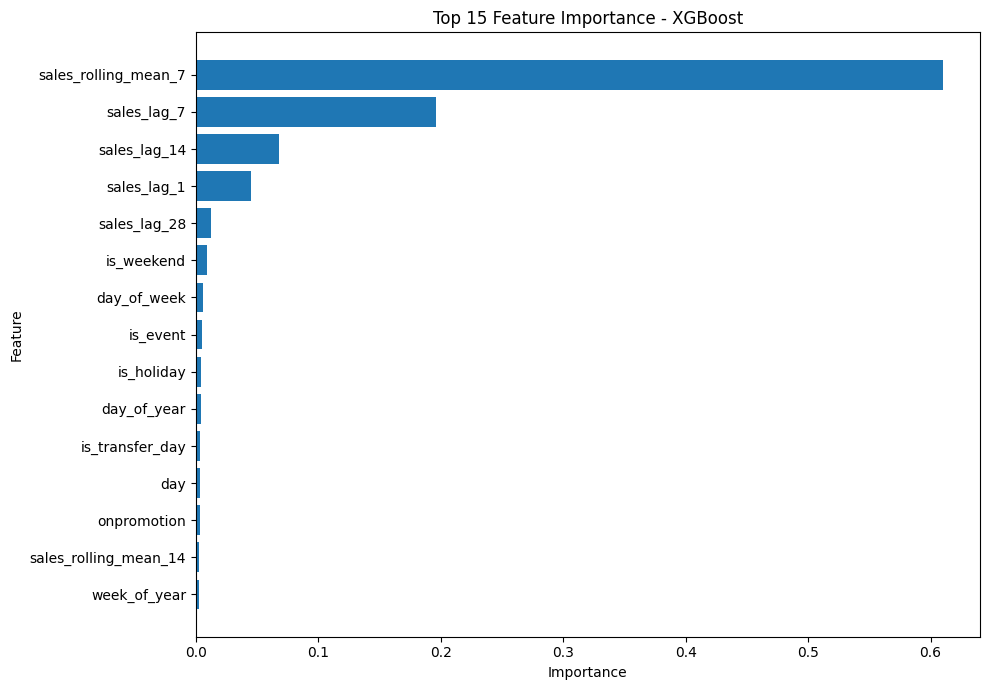

In [56]:
import matplotlib.pyplot as plt

top_features = feature_importance.head(15).sort_values(
    "importance",
    ascending=True
)

plt.figure(figsize=(10, 7))

plt.barh(
    top_features["feature"],
    top_features["importance"]
)

plt.title("Top 15 Feature Importance - XGBoost")
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.tight_layout()
plt.show()

In [57]:
prediction_sample = pd.DataFrame({
    "actual": y_valid,
    "predicted": y_pred
})

prediction_sample["error"] = (
    prediction_sample["actual"] -
    prediction_sample["predicted"]
).abs()

display(prediction_sample.head(20))

,actual,predicted,error
1654,2.0,5.950408,3.950408
1655,3.0,5.944064,2.944064
1656,7.0,5.617780,1.382220
1657,4.0,5.995700,1.995700
1658,10.0,5.181903,4.818097
1659,8.0,5.239340,2.760660
1660,0.0,-1.438026,1.438026
1661,4.0,5.477859,1.477859
1662,10.0,5.585294,4.414706
1663,2.0,6.847189,4.847189


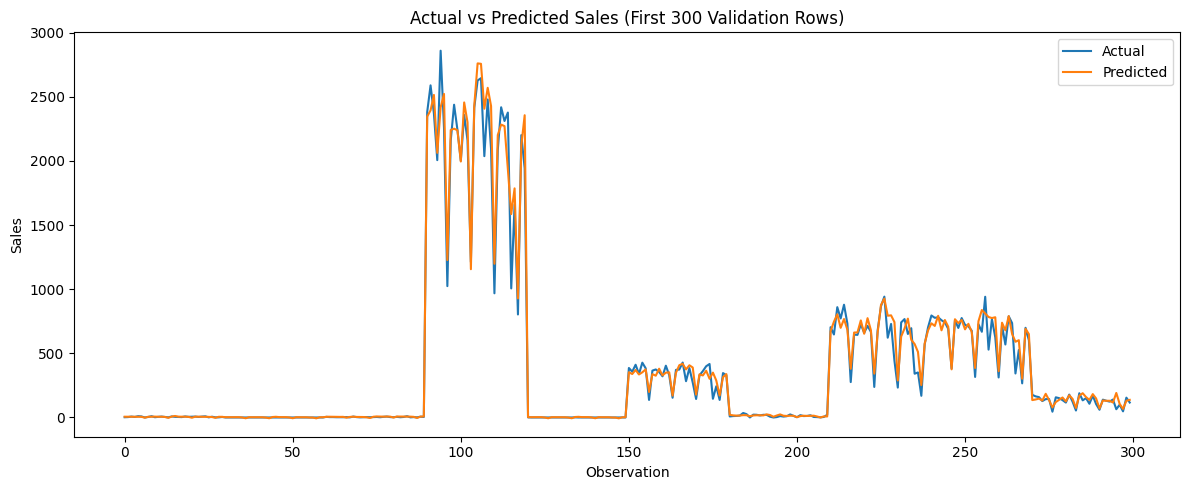

In [58]:
plt.figure(figsize=(12, 5))

plt.plot(
    y_valid.iloc[:300].to_numpy(),
    label="Actual"
)

plt.plot(
    y_pred[:300],
    label="Predicted"
)

plt.title("Actual vs Predicted Sales (First 300 Validation Rows)")
plt.xlabel("Observation")
plt.ylabel("Sales")
plt.legend()
plt.tight_layout()
plt.show()

In [59]:
prediction_sample = pd.DataFrame({
    "actual": y_valid.to_numpy(),
    "predicted": y_pred
})

prediction_sample["error"] = (
    prediction_sample["actual"] - prediction_sample["predicted"]
)

prediction_sample["absolute_error"] = prediction_sample["error"].abs()

display(prediction_sample.head(20).round(2))

,actual,predicted,error,absolute_error
0,2.0,5.95,-3.95,3.95
1,3.0,5.94,-2.94,2.94
2,7.0,5.62,1.38,1.38
3,4.0,6.00,-2.00,2.00
4,10.0,5.18,4.82,4.82
5,8.0,5.24,2.76,2.76
6,0.0,-1.44,1.44,1.44
7,4.0,5.48,-1.48,1.48
8,10.0,5.59,4.41,4.41
9,2.0,6.85,-4.85,4.85


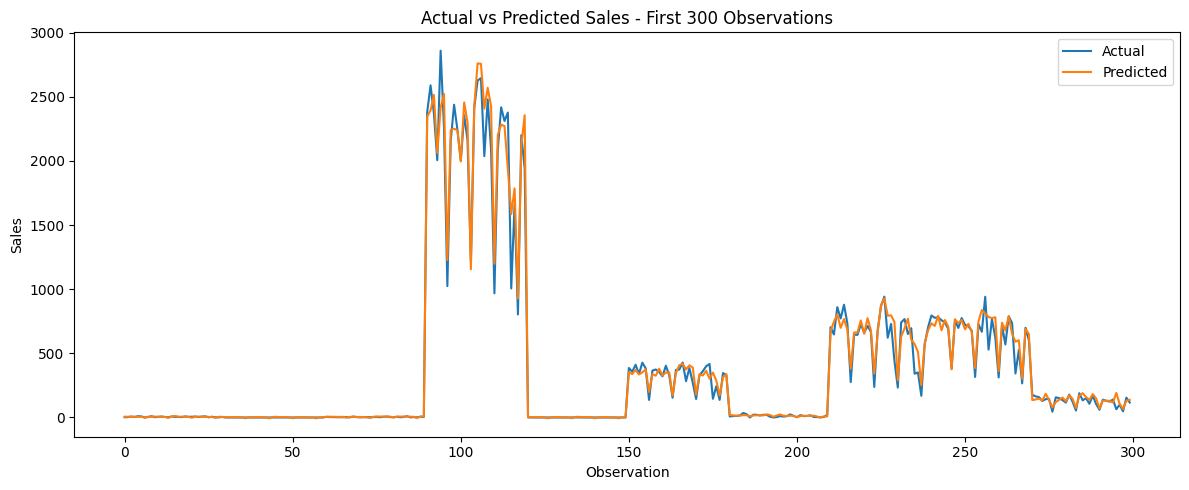

In [60]:
plt.figure(figsize=(12, 5))

plt.plot(
    prediction_sample["actual"].iloc[:300].to_numpy(),
    label="Actual"
)

plt.plot(
    prediction_sample["predicted"].iloc[:300].to_numpy(),
    label="Predicted"
)

plt.title("Actual vs Predicted Sales - First 300 Observations")
plt.xlabel("Observation")
plt.ylabel("Sales")
plt.legend()
plt.tight_layout()
plt.show()

In [61]:
from collections import defaultdict
import time
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 1. Siapkan riwayat penjualan aktual sampai 16 Juli 2017
history_data = train_fe.loc[
    train_fe["date"] < validation_start,
    ["store_nbr", "family", "date", "sales"]
].sort_values(["store_nbr", "family", "date"])

history = defaultdict(list)

for (store, family), group in history_data.groupby(["store_nbr", "family"]):
    history[(store, family)] = group["sales"].tolist()

# 2. Jalankan recursive forecasting selama periode validasi
recursive_results = []
validation_dates = sorted(valid_model["date"].unique())

start_time = time.time()

for current_date in validation_dates:

    day_data = valid_model.loc[
        valid_model["date"] == current_date
    ].copy()

    # Hitung ulang fitur historis dari actual/predicted history
    for idx, row in day_data.iterrows():

        key = (row["store_nbr"], row["family"])
        hist = history[key]

        day_data.at[idx, "sales_lag_1"] = hist[-1]
        day_data.at[idx, "sales_lag_7"] = hist[-7]
        day_data.at[idx, "sales_lag_14"] = hist[-14]
        day_data.at[idx, "sales_lag_28"] = hist[-28]

        day_data.at[idx, "sales_rolling_mean_7"] = np.mean(hist[-7:])
        day_data.at[idx, "sales_rolling_mean_14"] = np.mean(hist[-14:])
        day_data.at[idx, "sales_rolling_mean_28"] = np.mean(hist[-28:])

    # Siapkan fitur dan encoding kategori
    X_day = day_data[feature_columns].copy()

    X_day[categorical_features] = encoder.transform(
        X_day[categorical_features]
    )

    # Prediksi dan batasi nilai minimum menjadi nol
    day_pred = np.maximum(xgb_model.predict(X_day), 0)

    # Simpan hasil prediksi dan nilai aktual untuk evaluasi
    day_result = day_data[
        ["date", "store_nbr", "family", target]
    ].copy()

    day_result["predicted"] = day_pred

    recursive_results.append(day_result)

    # Masukkan PREDIKSI ke riwayat untuk hari berikutnya
    keys = day_data[["store_nbr", "family"]].itertuples(
        index=False, name=None
    )

    for key, prediction in zip(keys, day_pred):
        history[key].append(float(prediction))

# 3. Gabungkan hasil
recursive_result = pd.concat(
    recursive_results,
    ignore_index=True
)

recursive_result = recursive_result.rename(
    columns={target: "actual"}
)

recursive_result["error"] = (
    recursive_result["actual"] - recursive_result["predicted"]
)

recursive_result["absolute_error"] = (
    recursive_result["error"].abs()
)

recursive_time = time.time() - start_time

# 4. Hitung metrik evaluasi
recursive_rmse = np.sqrt(
    mean_squared_error(
        recursive_result["actual"],
        recursive_result["predicted"]
    )
)

recursive_mae = mean_absolute_error(
    recursive_result["actual"],
    recursive_result["predicted"]
)

recursive_r2 = r2_score(
    recursive_result["actual"],
    recursive_result["predicted"]
)

print("RECURSIVE FORECASTING VALIDATION")
print("--------------------------------")
print(f"Period       : {recursive_result['date'].min().date()} to {recursive_result['date'].max().date()}")
print(f"Total rows   : {len(recursive_result):,}")
print(f"RMSE         : {recursive_rmse:.4f}")
print(f"MAE          : {recursive_mae:.4f}")
print(f"R2           : {recursive_r2:.6f}")
print(f"Runtime      : {recursive_time:.2f} seconds")


C:\Users\ASUS\AppData\Local\Temp\ipykernel_24304\1225833530.py:39: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '5.428571428571429' has dtype incompatible with float32, please explicitly cast to a compatible dtype first.
  day_data.at[idx, "sales_rolling_mean_7"] = np.mean(hist[-7:])
C:\Users\ASUS\AppData\Local\Temp\ipykernel_24304\1225833530.py:40: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '4.357142857142857' has dtype incompatible with float32, please explicitly cast to a compatible dtype first.
  day_data.at[idx, "sales_rolling_mean_14"] = np.mean(hist[-14:])
C:\Users\ASUS\AppData\Local\Temp\ipykernel_24304\1225833530.py:41: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '4.535714285714286' has dtype incompatible with float32, please exp

RECURSIVE FORECASTING VALIDATION
--------------------------------
Period       : 2017-07-17 to 2017-08-15
Total rows   : 53,460
RMSE         : 219.5742
MAE          : 64.0782
R2           : 0.969747
Runtime      : 9.27 seconds


In [62]:
daily_forecast = (
    recursive_result
    .groupby("date")
    .agg(
        actual_sales=("actual", "sum"),
        predicted_sales=("predicted", "sum")
    )
    .reset_index()
)

daily_forecast["absolute_error"] = (
    daily_forecast["actual_sales"] -
    daily_forecast["predicted_sales"]
).abs()

daily_forecast["error_pct"] = (
    daily_forecast["absolute_error"] /
    daily_forecast["actual_sales"] * 100
)

display(daily_forecast.head(10).round(2))

,date,actual_sales,predicted_sales,absolute_error,error_pct
0,2017-07-17,818325.52,8.009695e+05,17356.02,2.12
1,2017-07-18,730133.71,7.466941e+05,16560.35,2.27
2,2017-07-19,767978.78,7.671176e+05,861.22,0.11
3,2017-07-20,688288.07,6.448972e+05,43390.82,6.30
4,2017-07-21,782418.30,7.582203e+05,24197.99,3.09
5,2017-07-22,932902.05,9.543439e+05,21441.89,2.30
6,2017-07-23,1024288.74,1.066707e+06,42418.38,4.14
7,2017-07-24,816564.33,7.723824e+05,44181.95,5.41
8,2017-07-25,713581.63,7.103966e+05,3185.07,0.45
9,2017-07-26,740653.04,7.243278e+05,16325.23,2.20


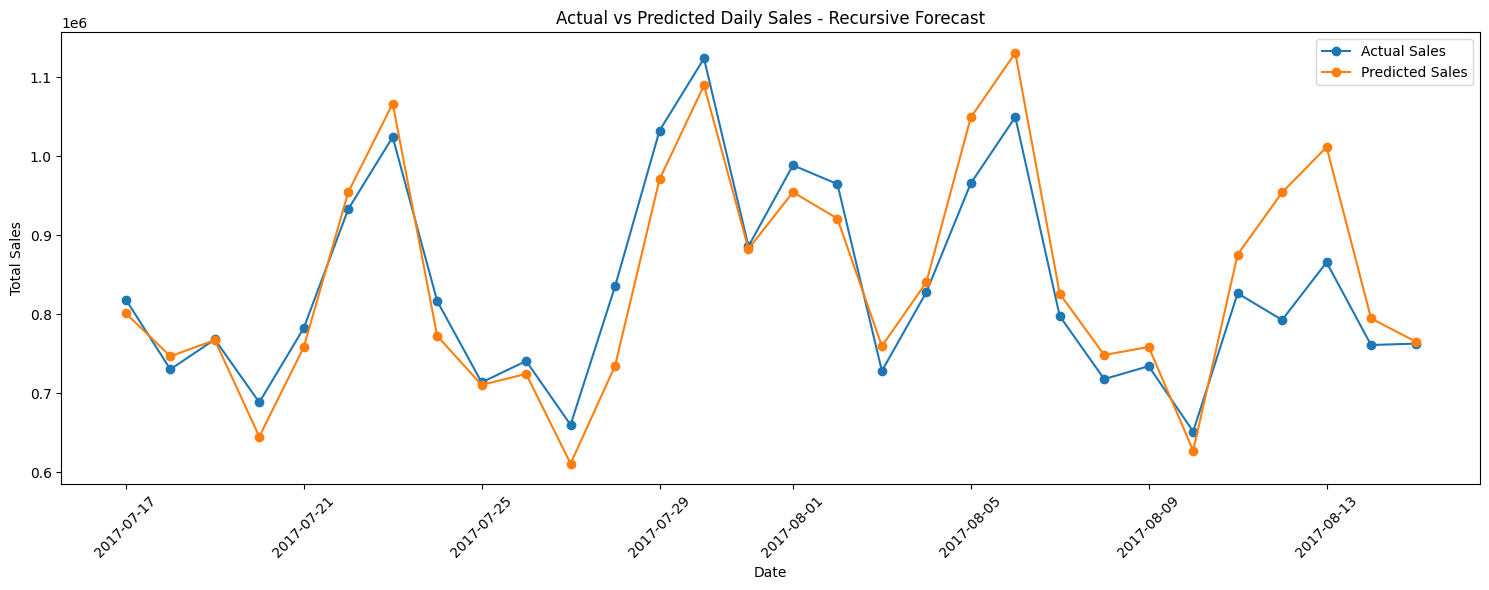

In [63]:
plt.figure(figsize=(15, 6))

plt.plot(
    daily_forecast["date"],
    daily_forecast["actual_sales"],
    label="Actual Sales",
    marker="o"
)

plt.plot(
    daily_forecast["date"],
    daily_forecast["predicted_sales"],
    label="Predicted Sales",
    marker="o"
)

plt.title("Actual vs Predicted Daily Sales - Recursive Forecast")
plt.xlabel("Date")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

In [64]:
daily_wape = (
    daily_forecast["absolute_error"].sum()
    / daily_forecast["actual_sales"].sum()
) * 100

daily_bias = (
    daily_forecast["predicted_sales"].sum()
    - daily_forecast["actual_sales"].sum()
) / daily_forecast["actual_sales"].sum() * 100

print(f"Daily WAPE       : {daily_wape:.2f}%")
print(f"Daily Bias       : {daily_bias:.2f}%")
print(f"Actual Total     : {daily_forecast['actual_sales'].sum():,.2f}")
print(f"Predicted Total  : {daily_forecast['predicted_sales'].sum():,.2f}")

Daily WAPE       : 5.06%
Daily Bias       : 1.06%
Actual Total     : 24,985,326.80
Predicted Total  : 25,250,248.00


In [65]:
from sklearn.preprocessing import OrdinalEncoder
from xgboost import XGBRegressor
import time

# Siapkan seluruh data historis
X_final = model_data[feature_columns].copy()
y_final = model_data[target].copy()

# Encoding categorical features
encoder_final = OrdinalEncoder(
    handle_unknown="use_encoded_value",
    unknown_value=-1
)

X_final[categorical_features] = encoder_final.fit_transform(
    X_final[categorical_features]
)

# Konfigurasi model final
final_model = XGBRegressor(
    n_estimators=300,
    max_depth=8,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="reg:squarederror",
    tree_method="hist",
    n_jobs=4,
    random_state=42
)

# Training
start_time = time.time()

final_model.fit(X_final, y_final, verbose=False)

final_training_time = time.time() - start_time

print("FINAL MODEL TRAINING")
print("--------------------")
print(f"Training records : {len(X_final):,}")
print(f"Features         : {len(feature_columns)}")
print(f"Training period  : {model_data['date'].min().date()} to {model_data['date'].max().date()}")
print(f"Training time    : {final_training_time:.2f} seconds")

FINAL MODEL TRAINING
--------------------
Training records : 2,950,992
Features         : 28
Training period  : 2013-01-29 to 2017-08-15
Training time    : 82.93 seconds


In [66]:
from collections import defaultdict

history_test = defaultdict(list)

history_data_test = (
    train_fe[
        ["store_nbr", "family", "date", "sales"]
    ]
    .sort_values(["store_nbr", "family", "date"])
)

for (store, family), group in history_data_test.groupby(
    ["store_nbr", "family"]
):
    history_test[(store, family)] = (
        group["sales"].astype(float).tolist()
    )

print("Jumlah series:", len(history_test))
print("Contoh panjang history:", len(next(iter(history_test.values()))))


Jumlah series: 1782
Contoh panjang history: 1684


In [67]:

test_recursive_results = []

test_dates = sorted(test_fe["date"].unique())

for current_date in test_dates:

    day_data = test_fe.loc[
        test_fe["date"] == current_date
    ].copy()

    day_data = day_data.sort_values(
        ["store_nbr", "family"]
    )

    for idx, row in day_data.iterrows():

        key = (row["store_nbr"], row["family"])
        hist = history_test[key]

        day_data.at[idx, "sales_lag_1"] = hist[-1]
        day_data.at[idx, "sales_lag_7"] = hist[-7]
        day_data.at[idx, "sales_lag_14"] = hist[-14]
        day_data.at[idx, "sales_lag_28"] = hist[-28]

        day_data.at[idx, "sales_rolling_mean_7"] = np.mean(hist[-7:])
        day_data.at[idx, "sales_rolling_mean_14"] = np.mean(hist[-14:])
        day_data.at[idx, "sales_rolling_mean_28"] = np.mean(hist[-28:])

    X_day = day_data[feature_columns].copy()

    X_day[categorical_features] = encoder.transform(
        X_day[categorical_features]
    )

    day_pred = np.maximum(
        xgb_model.predict(X_day),
        0
    )

    day_result = day_data[
        ["id", "date", "store_nbr", "family"]
    ].copy()

    day_result["predicted_sales"] = day_pred

    test_recursive_results.append(day_result)

    keys = day_data[
        ["store_nbr", "family"]
    ].itertuples(index=False, name=None)

    for key, prediction in zip(keys, day_pred):
        history_test[key].append(float(prediction))

test_forecast = pd.concat(
    test_recursive_results,
    ignore_index=True
)

print("TEST FORECAST COMPLETED")
print("-----------------------")
print("Total records:", len(test_forecast))
print("First date:", test_forecast["date"].min())
print("Last date:", test_forecast["date"].max())

display(test_forecast.head(10))


TEST FORECAST COMPLETED
-----------------------
Total records: 28512
First date: 2017-08-16 00:00:00
Last date: 2017-08-31 00:00:00


,id,date,store_nbr,family,predicted_sales
0,3000888,2017-08-16,1,AUTOMOTIVE,5.228926
1,3000889,2017-08-16,1,BABY CARE,2.184887
2,3000890,2017-08-16,1,BEAUTY,9.717563
3,3000891,2017-08-16,1,BEVERAGES,2245.561279
4,3000892,2017-08-16,1,BOOKS,2.184887
5,3000893,2017-08-16,1,BREAD/BAKERY,375.096344
6,3000894,2017-08-16,1,CELEBRATION,11.910309
7,3000895,2017-08-16,1,CLEANING,754.839050
8,3000896,2017-08-16,1,DAIRY,835.773071
9,3000897,2017-08-16,1,DELI,148.937393


In [68]:

daily_test_forecast = (
    test_forecast
    .groupby("date")
    .agg(
        predicted_sales=("predicted_sales", "sum"),
        total_records=("id", "count")
    )
    .reset_index()
)

display(daily_test_forecast.round(2))


,date,predicted_sales,total_records
0,2017-08-16,8.826382e+05,1782
1,2017-08-17,7.005704e+05,1782
2,2017-08-18,7.996094e+05,1782
3,2017-08-19,9.255783e+05,1782
4,2017-08-20,1.007831e+06,1782
5,2017-08-21,7.881969e+05,1782
6,2017-08-22,7.371665e+05,1782
7,2017-08-23,7.761226e+05,1782
8,2017-08-24,6.575782e+05,1782
9,2017-08-25,7.864718e+05,1782


In [69]:

family_forecast = (
    test_forecast
    .groupby("family")
    .agg(
        predicted_sales=("predicted_sales", "sum"),
        average_sales=("predicted_sales", "mean")
    )
    .sort_values("predicted_sales", ascending=False)
    .reset_index()
)

display(family_forecast.round(2))


,family,predicted_sales,average_sales
0,GROCERY I,3.732628e+06,4320.169922
1,BEVERAGES,2.857996e+06,3307.870117
2,PRODUCE,1.989886e+06,2303.110107
3,CLEANING,9.245028e+05,1070.030029
4,DAIRY,6.921517e+05,801.099976
5,BREAD/BAKERY,4.410747e+05,510.500000
6,MEATS,3.091127e+05,357.769989
7,POULTRY,3.081334e+05,356.640015
8,SCHOOL AND OFFICE SUPPLIES,2.967199e+05,343.429993
9,PERSONAL CARE,2.554260e+05,295.630005


In [70]:

store_forecast = (
    test_forecast
    .groupby("store_nbr")
    .agg(
        predicted_sales=("predicted_sales", "sum"),
        average_sales=("predicted_sales", "mean")
    )
    .sort_values("predicted_sales", ascending=False)
    .reset_index()
)

display(store_forecast.round(2))


,store_nbr,predicted_sales,average_sales
0,44,667755.000000,1264.689941
1,45,601840.875000,1139.849976
2,47,551793.125000,1045.060059
3,3,542159.562500,1026.819946
4,49,507084.437500,960.390015
5,46,431989.093750,818.159973
6,51,368033.125000,697.030029
7,48,367935.375000,696.849976
8,52,358411.375000,678.809998
9,8,328369.656250,621.909973


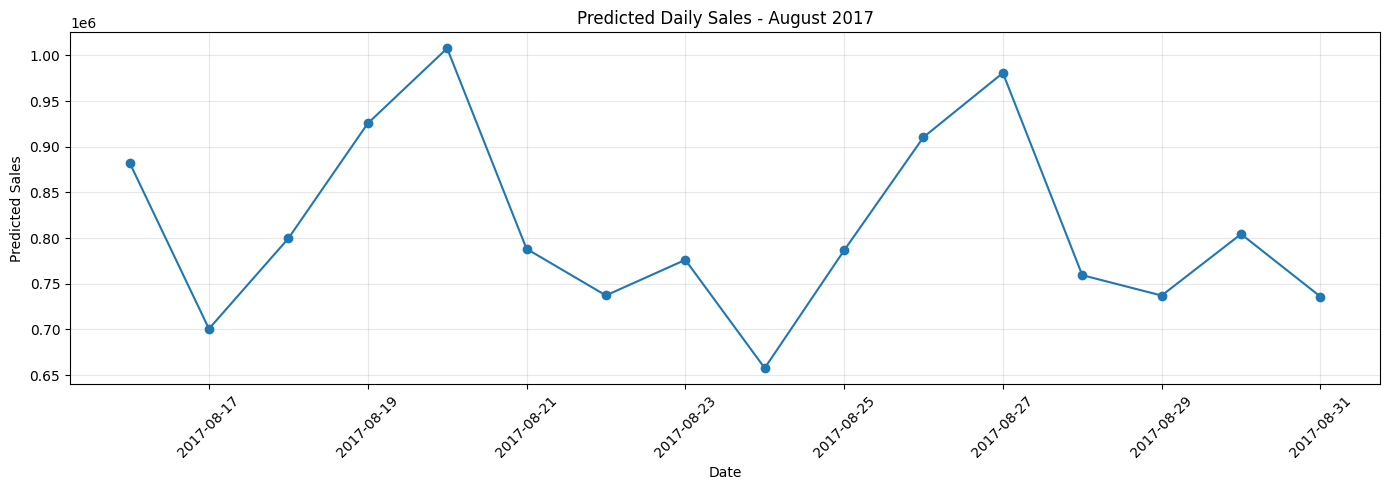

In [71]:

plt.figure(figsize=(14, 5))

plt.plot(
    daily_test_forecast["date"],
    daily_test_forecast["predicted_sales"],
    marker="o"
)

plt.title("Predicted Daily Sales - August 2017")
plt.xlabel("Date")
plt.ylabel("Predicted Sales")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


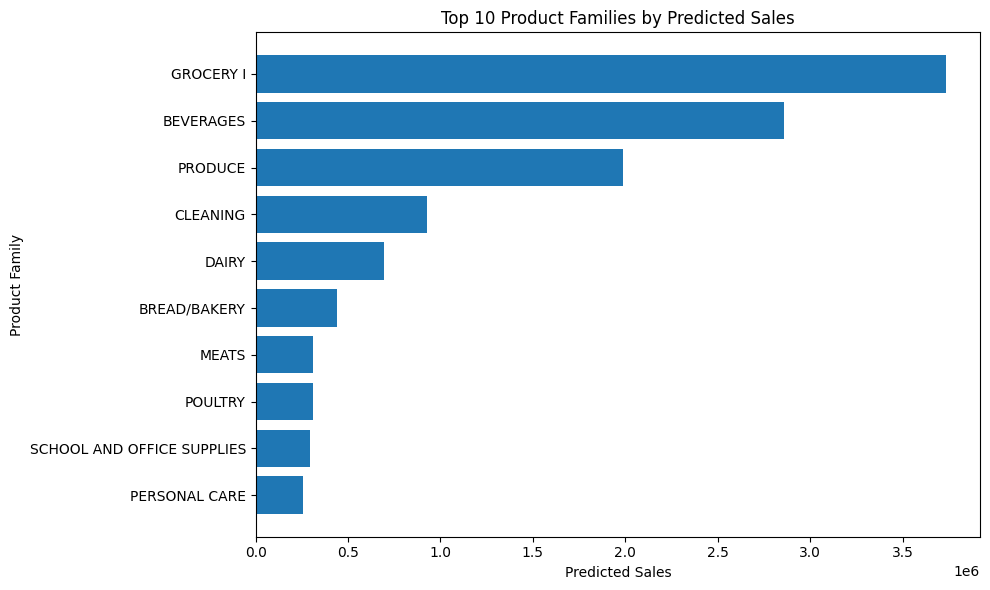

In [72]:

top_family = family_forecast.head(10).sort_values(
    "predicted_sales"
)

plt.figure(figsize=(10, 6))

plt.barh(
    top_family["family"],
    top_family["predicted_sales"]
)

plt.title("Top 10 Product Families by Predicted Sales")
plt.xlabel("Predicted Sales")
plt.ylabel("Product Family")
plt.tight_layout()
plt.show()


In [73]:
print("FORECAST DATA VALIDATION")
print("=" * 40)

print("Total records:", len(test_forecast))
print("Expected records:", len(test) )

print(
    "Duplicate IDs:",
    test_forecast["id"].duplicated().sum()
)

print(
    "Duplicate date-store-family:",
    test_forecast.duplicated(
        ["date", "store_nbr", "family"]
    ).sum()
)

print(
    "Missing values:\n",
    test_forecast.isna().sum()
)

print(
    "Negative predictions:",
    (test_forecast["predicted_sales"] < 0).sum()
)

print(
    "Unique dates:",
    test_forecast["date"].nunique()
)

print(
    "Unique stores:",
    test_forecast["store_nbr"].nunique()
)

print(
    "Unique families:",
    test_forecast["family"].nunique()
)

FORECAST DATA VALIDATION
Total records: 28512
Expected records: 28512
Duplicate IDs: 0
Duplicate date-store-family: 0
Missing values:
 id                 0
date               0
store_nbr          0
family             0
predicted_sales    0
dtype: int64
Negative predictions: 0
Unique dates: 16
Unique stores: 54
Unique families: 33


In [74]:
print(test_forecast.shape)
print(test_forecast.head())

(28512, 5)
        id       date  store_nbr      family  predicted_sales
0  3000888 2017-08-16          1  AUTOMOTIVE         5.228926
1  3000889 2017-08-16          1   BABY CARE         2.184887
2  3000890 2017-08-16          1      BEAUTY         9.717563
3  3000891 2017-08-16          1   BEVERAGES      2245.561279
4  3000892 2017-08-16          1       BOOKS         2.184887


In [75]:
pip install pyarrow

Note: you may need to restart the kernel to use updated packages.


In [76]:
from pathlib import Path

OUTPUT_DIR = Path("../../data/processed")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

forecast_path = OUTPUT_DIR / "sales_forecast.csv"

test_forecast.to_csv(
    forecast_path,
    index=False
)

print("Forecast berhasil disimpan!")
print("Lokasi:", forecast_path.resolve())
print("Total records:", len(test_forecast))

Forecast berhasil disimpan!
Lokasi: D:\04 Porto\ecommerce-data-intelligence\data\processed\sales_forecast.csv
Total records: 28512


In [77]:
forecast_check = pd.read_csv(
    forecast_path,
    parse_dates=["date"]
)

print("Shape:", forecast_check.shape)
print("\nMissing values:")
print(forecast_check.isna().sum())
print("\nPreview:")
display(forecast_check.head())

Shape: (28512, 5)

Missing values:
id                 0
date               0
store_nbr          0
family             0
predicted_sales    0
dtype: int64

Preview:


,id,date,store_nbr,family,predicted_sales
0,3000888,2017-08-16,1,AUTOMOTIVE,5.228926
1,3000889,2017-08-16,1,BABY CARE,2.184887
2,3000890,2017-08-16,1,BEAUTY,9.717563
3,3000891,2017-08-16,1,BEVERAGES,2245.561300
4,3000892,2017-08-16,1,BOOKS,2.184887
